# 05 A Transformer trained from scratch (control experiment)

**Question:** is the Transformer *architecture* enough, or does the benefit come from *pre-training* on large text corpora?

We train a small BERT-style encoder (Devlin et al., 2019) whose weights all start random and which sees only our 608
training articles. It uses its own WordPiece tokeniser learned from the same articles. If it does much worse than the
fine-tuned pretrained models in notebook 06, the gain there comes from what was learned during pre-training, not from
self-attention itself. This runs on a CPU in a few minutes.

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

# Change this to your own GitHub repository before running in Colab
REPO_URL = "https://github.com/YOUR-GITHUB-USERNAME/lingala-news-classification.git"

if IN_COLAB and not Path("lingala-news-classification").exists():
    !git clone -q {REPO_URL}
if IN_COLAB:
    %cd lingala-news-classification
    %pip install -q -r requirements.txt

if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
print("Working directory:", os.getcwd())

Working directory: /home/claude/lingala-news-classification


In [2]:
import pandas as pd
import torch

from src import config, data_loading, evaluation, plots, scratch_transformer, transformer_training
from src.experiment_log import log_experiment

MODEL_FAMILY = "transformer_scratch"
train, validation, test = data_loading.load_all_splits()
validation_ids = data_loading.labels_to_ids(validation["category"])
test_ids = data_loading.labels_to_ids(test["category"])

tokenizer = scratch_transformer.train_wordpiece_tokeniser(
    train[config.TEXT_COLUMN], vocabulary_size=8000, directory=config.MODELS_DIRECTORY / "scratch_tokeniser")
print("Vocabulary size:", tokenizer.vocab_size)
print("Subword statistics on train:", transformer_training.subword_statistics(tokenizer, train[config.TEXT_COLUMN]))
print(tokenizer.tokenize(train[config.TEXT_COLUMN].iloc[1])[:30])




Vocabulary size: 8000


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (673 > 512). Running this sequence through the model will result in indexing errors


Subword statistics on train: {'tokens_per_word': 1.264, 'share_truncated_at_512': 0.008}
['fmi', 'elobi', 'kokitisa', 'budget', 'ezali', 'malamu', '.', 'fmi', '(', 'fonds', 'monétaire', 'international', ')', 'etalisi', 'kobanga', 'na', 'yango', 'lolenge', 'bosaleli', 'budget', 'ya', 'rdc', 'ezali', 'kokende', 'mpe', 'ekanisi', 'ete', 'ekozala', 'malamu', 'kokitisa']


In [3]:
BASE = {"hidden_size": 128, "layers": 2, "heads": 4, "max_tokens": 256, "strategy": "head",
        "learning_rate": 5e-4, "batch_size": 16, "epochs": 40, "patience": 8, "class_weight": True,
        "seed": config.RANDOM_SEED}
results, histories = [], {}

def run(name, changes, notes, seed=config.RANDOM_SEED, evaluate_on=None):
    settings = {**BASE, **changes, "seed": seed}
    model = scratch_transformer.build_scratch_model(tokenizer, settings)
    model, _, history = transformer_training.run_experiment(settings, train, validation, model=model, tokenizer=tokenizer)
    probabilities = transformer_training.predict_probabilities(model, tokenizer, validation, settings)
    scores = evaluation.compute_scores(validation_ids, probabilities)
    scores["parameters"] = scratch_transformer.count_parameters(model)
    log_experiment(MODEL_FAMILY, name, "validation", settings, scores, notes)
    results.append({"experiment": name, "change": notes, "parameters": scores["parameters"],
                    "macro_f1": scores["macro_f1"], "weighted_f1": scores["weighted_f1"], "best_epoch": history["best_epoch"]})
    histories[name] = history
    return model, settings

In [4]:
torch.set_num_threads(max(1, torch.get_num_threads()))
run("T1_2layers_128d", {}, "2 layers, hidden 128, 256 tokens")
run("T2_4layers_256d", {"layers": 4, "hidden_size": 256, "learning_rate": 3e-4}, "Bigger: 4 layers, hidden 256")
run("T3_2layers_512tokens", {"max_tokens": 512}, "Longer input: 512 tokens")
summary = pd.DataFrame(results)
summary

Epoch 1: train loss 1.3860, validation loss 1.3527, macro-F1 0.1825


Epoch 2: train loss 1.3896, validation loss 1.3862, macro-F1 0.0515


Epoch 3: train loss 1.3851, validation loss 1.3534, macro-F1 0.4021


Epoch 4: train loss 0.9176, validation loss 0.6771, macro-F1 0.6550


Epoch 5: train loss 0.4962, validation loss 0.9401, macro-F1 0.5554


...

Epoch 13: train loss 0.0049, validation loss 0.7660, macro-F1 0.7967


Epoch 14: train loss 0.0041, validation loss 0.7765, macro-F1 0.7865


Epoch 15: train loss 0.0036, validation loss 0.7890, macro-F1 0.7865
Early stopping


Logged 'T3_2layers_512tokens' (validation) to transformer_scratch.csv


,experiment,change,parameters,macro_f1,weighted_f1,best_epoch
0,T1_2layers_128d,"2 layers, hidden 128, 256 tokens",1470852,0.8438,0.8635,8
1,T2_4layers_256d,"Bigger: 4 layers, hidden 256",5340420,0.7687,0.8470,7
2,T3_2layers_512tokens,Longer input: 512 tokens,1503620,0.8088,0.8825,7


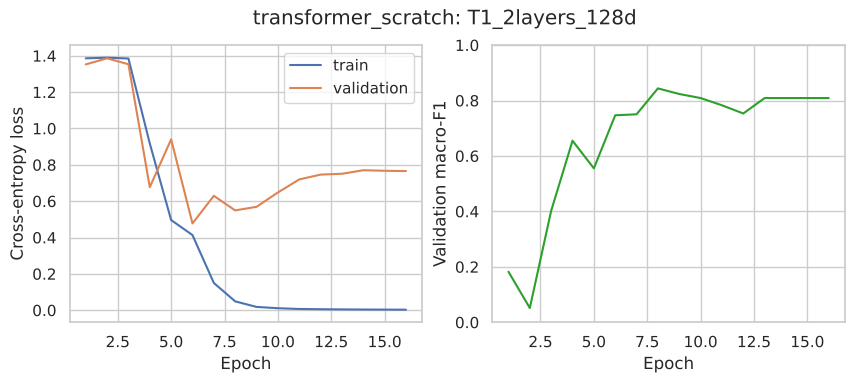

In [5]:
plots.plot_learning_curves(histories["T1_2layers_128d"], "transformer_scratch", "T1_2layers_128d");

## Final: best configuration, three seeds, test set

In [6]:
best = summary.sort_values("macro_f1", ascending=False).iloc[0]["experiment"]
changes = {"T1_2layers_128d": {}, "T2_4layers_256d": {"layers": 4, "hidden_size": 256, "learning_rate": 3e-4},
           "T3_2layers_512tokens": {"max_tokens": 512}}[best]
seed_scores, first_probabilities = [], None
for seed in config.FINAL_RUN_SEEDS:
    settings = {**BASE, **changes, "seed": seed}
    model = scratch_transformer.build_scratch_model(tokenizer, settings)
    model, _, _ = transformer_training.run_experiment(settings, train, validation, model=model, tokenizer=tokenizer)
    probabilities = transformer_training.predict_probabilities(model, tokenizer, test, settings)
    seed_scores.append(evaluation.compute_scores(test_ids, probabilities))
    first_probabilities = probabilities if first_probabilities is None else first_probabilities

summary_scores = evaluation.summarise_runs(seed_scores)
summary_scores["macro_f1_ci_low"], summary_scores["macro_f1_ci_high"] = evaluation.bootstrap_confidence_interval(test_ids, first_probabilities.argmax(1))
log_experiment(MODEL_FAMILY, f"FINAL_{best}", "test", {**BASE, **changes, "seeds": config.FINAL_RUN_SEEDS}, summary_scores, "Mean/std over 3 seeds")
evaluation.save_test_predictions(first_probabilities, "transformer_scratch")
print(f"{best}: test macro-F1 {summary_scores['macro_f1']:.3f} ± {summary_scores['macro_f1_std']:.3f}")
evaluation.print_classification_report(test_ids, first_probabilities)

Epoch 1: train loss 1.3875, validation loss 1.3711, macro-F1 0.1825


Epoch 2: train loss 1.3896, validation loss 1.3768, macro-F1 0.0515


Epoch 3: train loss 1.3889, validation loss 1.3663, macro-F1 0.3339


Epoch 4: train loss 1.0411, validation loss 0.7204, macro-F1 0.6643


Epoch 5: train loss 0.5312, validation loss 0.5735, macro-F1 0.6595


...

Epoch 10: train loss 0.0111, validation loss 1.1552, macro-F1 0.7055


Epoch 11: train loss 0.0082, validation loss 1.1180, macro-F1 0.7507


Epoch 12: train loss 0.0064, validation loss 1.1752, macro-F1 0.7459


Epoch 13: train loss 0.0051, validation loss 1.2259, macro-F1 0.7453
Early stopping


Logged 'FINAL_T1_2layers_128d' (test) to transformer_scratch.csv
Saved test probabilities to /home/claude/lingala-news-classification/results/predictions/transformer_scratch.csv
T1_2layers_128d: test macro-F1 0.752 ± 0.041
              precision    recall  f1-score   support

    politics      0.875     0.910     0.892       100
      health      0.939     0.795     0.861        39
      sports      0.947     0.947     0.947        19
    business      0.368     0.412     0.389        17

    accuracy                          0.840       175
   macro avg      0.783     0.766     0.772       175
weighted avg      0.848     0.840     0.842       175



**Interpretation.** Self-attention has many parameters and no built-in knowledge of language; with 608 articles it has to
learn word meanings, Lingala morphology and the topics all at once. Compare this score with the bag-of-words models (notebook 02)
and the fine-tuned pretrained models (notebook 06): the architecture alone does not explain the gains of pretrained Transformers.